<a href="https://colab.research.google.com/github/Imran1hp/Atomica-website-/blob/main/image_labeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
!pip install -q autodistill-grounding-dino supervision

In [5]:

from autodistill.detection import CaptionOntology
from autodistill_grounding_dino import GroundingDINO

ontology = CaptionOntology({
    "apple": "organic",
    "banana": "organic",
    "orange": "organic",
    "carrot": "organic",
    "potato": "organic",
    "onion": "organic",
    "cabbage": "organic",
    "vegetable peel": "organic",
    "fruit peel": "organic",
    "food scraps": "organic",
    "plant leaf": "organic",
})


model = GroundingDINO(ontology=ontology)

model.label(
    input_folder="/content/drive/MyDrive/test_organic_images/Organic waste",
    extension=".jpg",
    output_folder="/content/data_labeled",
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
trying to load grounding dino directly
final text_encoder_type: bert-base-uncased


Labeling /content/drive/MyDrive/test_organic_images/Organic waste/Image_97.jpg: 100%|██████████| 88/88 [08:05<00:00,  5.52s/it]


Labeled dataset created - ready for distillation.


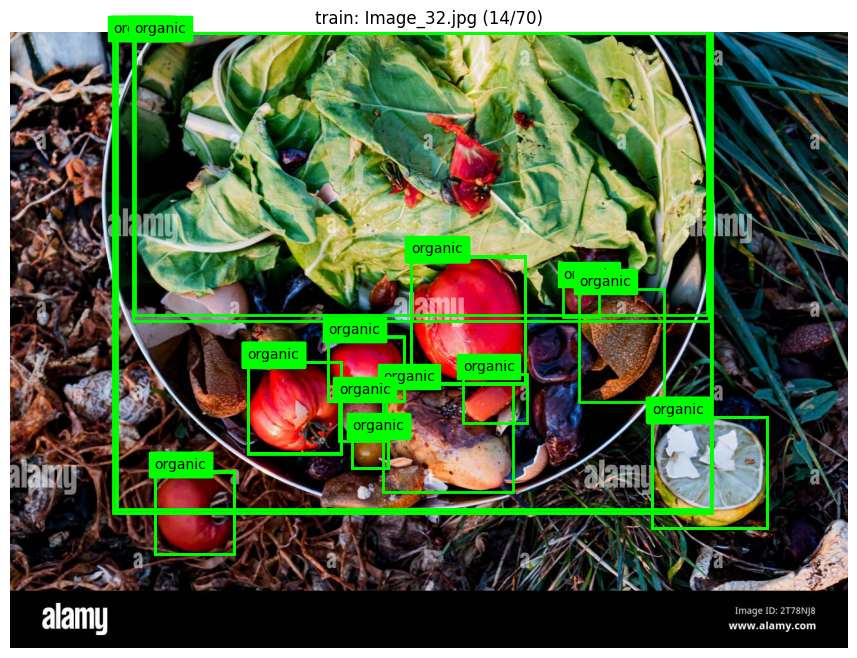

In [6]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

DATASET = Path("/content/data_labeled")  # change if needed
SPLIT = "train"  # change to "valid" to review validation images

images_dir = DATASET / SPLIT / "images"
labels_dir = DATASET / SPLIT / "labels"

image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

# Read class names from data.yaml if available
names = {}
yaml_path = DATASET / "data.yaml"
if yaml_path.exists():
    import yaml
    config = yaml.safe_load(yaml_path.read_text())
    class_names = config.get("names", [])
    if isinstance(class_names, list):
        names = dict(enumerate(class_names))
    elif isinstance(class_names, dict):
        names = {int(k): v for k, v in class_names.items()}

if not image_paths:
    raise FileNotFoundError(f"No images found in {images_dir}")

index = widgets.IntSlider(
    value=0, min=0, max=len(image_paths)-1, step=1,
    description="Image", continuous_update=False
)
out = widgets.Output()

def show_image(i):
    image_path = image_paths[i]
    label_path = labels_dir / f"{image_path.stem}.txt"

    img = Image.open(image_path).convert("RGB")
    width, height = img.size
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(img)
    ax.set_title(f"{SPLIT}: {image_path.name} ({i+1}/{len(image_paths)})")
    ax.axis("off")

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                print(f"Skipping malformed label: {line}")
                continue

            class_id = int(float(parts[0]))
            cx, cy, bw, bh = map(float, parts[1:])

            # YOLO labels use normalized center x/y and width/height
            x1 = (cx - bw / 2) * width
            y1 = (cy - bh / 2) * height
            box_w = bw * width
            box_h = bh * height

            rect = plt.Rectangle(
                (x1, y1), box_w, box_h,
                fill=False, edgecolor="lime", linewidth=2
            )
            ax.add_patch(rect)
            ax.text(
                x1, max(0, y1 - 5),
                names.get(class_id, str(class_id)),
                color="black", backgroundcolor="lime", fontsize=10
            )
    else:
        ax.text(10, 25, "No matching label file", color="red",
                bbox=dict(facecolor="white", alpha=.8))

    plt.show()
    plt.close(fig)

def update(change=None):
    with out:
        clear_output(wait=True)
        show_image(index.value)

index.observe(update, names="value")
display(index, out)
update()